# Destination choice in practice: resource use, cutoffs and local re-solving

**Question:** How do capacity limits and restricted re-solving change a destination-aware schedule?

**Level**: 2

**Prerequisites**: topic 01, CPIT formulation and package setup

**Reading time**: 38 minutes

## Objectives





## Setup

From the repository root, install the exact pinned environment. This cell reports the versions actually imported. The notebook never installs packages at runtime.

```bash
pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Import the pinned package, plotting tools and PhaseFlow instance builder.
import importlib.metadata as metadata
import json
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.5
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Data

The example is the 48-block vein twin generated from seed 31 by PhaseFlow's MIT-licensed instance builder and OreBlocks 0.6.5. The committed twin-vein manifest is read only as provenance context; the schedule is computed from the explicitly reconstructed case. MineLib data are not used: its Newman1 result is an aggregate-only fixed-destination CPIT record under academic-download terms, not redistributable block data or a PCPSP comparator.

Reconstruct the documented teaching case rather than copying its trace into a result. Seed 31 fixes the generated deposit. The manifest at `data/derived/manifests/twin-vein.json` records the committed case's declared context and methods; the block arrays below are built afresh by the pipeline. These sources have different roles: manifest as provenance, seeded generator as experimental input. A deterministic seed supports repeatability, not geological truth. The small case is deliberately used to make destination alternatives and period assignments inspectable. The code below rebuilds exactly the dimensions and scenario stated here; when experimenting, alter the seed explicitly and record every changed capacity or economic assumption.

Build the input through PhaseFlow's typed `Case` and `Scenario` contract. The two resource rows represent mining and processing; their fractions are capacity assumptions, not measured plant limits. We inspect the contract report before passing the instance to the scheduling methods.

In [2]:
# Rebuild the seeded teaching instance and read the committed provenance record.
case = Case(
    id='nb-destination-vein-4x4x3', category='teaching',
    title_en='Destination lesson', title_es='Leccion de destinos',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(periods=4, discount_rate=0.08,
                      capacity_fraction=(0.70, 0.50),
                      resource_names=('mining', 'processing')),
)
instance = build_instance(case)
manifest = json.loads(Path('../../../data/derived/manifests/twin-vein.json').read_text(encoding='utf-8'))
print('contract accepted:', instance.report.ok)
print('blocks:', instance.n_blocks, '| resources:', instance.pcpsp.n_resources,
      '| destinations:', instance.pcpsp.n_destinations)
print('committed provenance case:', manifest['case_id'])

contract accepted: True
blocks: 48 | resources: 2 | destinations: 2
committed provenance case: twin-vein


## Method

We begin with the continuous relaxation because it supplies an upper reference for every feasible integer schedule in the same PCPSP formulation. The package can return its expected-time and destination-share vectors, which are fractional diagnostics. Next we generate a feasible plan through destination-aware TopoSort. Finally the local re-solve explores bounded neighborhoods and jointly changes periods and destinations. The sequence shows how a bound, a constructive method and a restricted exact method complement one another.

The modeling step is to preserve destination-specific economics and resource coefficients from block creation through schedule evaluation. Let z[b,d,t] indicate that block b is extracted in period t and sent to destination d. The value term is discounted by period. Each resource row sums the selected destination coefficient, and the precedence constraints apply to extraction regardless of destination. In the package model, `Pcpsp.value` has one value per block and destination, while `Pcpsp.coef` has one resource vector per block and destination. `to_cpit()` is the fixed best-destination reduction, useful as context but not a substitute for the joint choice.

The first computation solves the PCPSP LP relaxation with its solution vectors enabled. Besides the objective bound, the result can expose fractional expected extraction times and destination shares. These values explain what the relaxation prefers; they are not a feasible integer plan. We retain the solve status and model dimensions so the bound has visible provenance. If a model is too large for a configured row limit, the package can return no direct LP result; a missing result must be reported rather than replaced with a fabricated number.

Destination-aware TopoSort is the constructive baseline. It orders blocks by the package's destination-aware weight, checks prerequisite periods, then examines each allowed destination. For each destination it finds the earliest period whose remaining resource capacity can accept that block. It selects the alternative with the largest discounted value among those earliest placements. That policy is deterministic for the fixed input. It guarantees the capacity rows by construction but does not enforce general blending constraints, which this case does not declare.

The second schedule is a restricted exact re-solve around the TopoSort incumbent. `exact_destination_local_search` selects a neighborhood of blocks and jointly re-optimizes their periods and destinations while keeping the other blocks fixed. The neighborhood model is exact for its restricted variables; the complete schedule is not thereby proven globally optimal. Each accepted move improves or preserves the incumbent, so the final objective cannot be below the start. We set the random seed, neighborhood size, round count and solver time limit explicitly, making this experiment repeatable and bounded.

The schedule scorer independently recomputes discounted value and resource use from the period and destination arrays. We compare the scorer's NPV with the method object's NPV and tabulate resource slack by period. The arrays retain a negative sentinel for unmined blocks. For mined blocks, destination IDs refer to the package model's declared alternatives; never infer plant/waste from grade alone, because a positive net value or a threshold can disagree with the stored alternative economics.

A fixed-destination CPIT schedule provides a useful third row. It uses the value and resource coefficients returned by the instance's CPIT reduction and cannot decide plant versus waste while scheduling. Its result is only a heuristic for the reduced problem. The PCPSP relaxation is a bound for the destination-choice formulation, and the CPIT schedule is feasible for its own fixed-coefficient formulation. Reporting both values is an experiment in model flexibility, not a license to rank unlike formulations under one gap denominator.

The first figure puts the two destination-aware plans beside their relaxation bound. It makes the improvement from restricted re-solving visible and shows remaining relaxation headroom. The bound is not a third schedule, and a small gap does not prove global optimality unless the method solves the full integer problem. The second figure separates plant and waste block counts by period. This exposes cutoff movement and resource competition without implying that the mined tonnage equals block count; the notebook keeps those units distinct.

Interpret the effective cutoff as a consequence of scheduling, not a fixed input threshold. The package's destination-aware routine may delay a block for the plant or send it to waste, depending on which alternative fits and yields more discounted value. The cutoff plot is descriptive of the selected blocks and can be non-monotone across periods as capacity, precedence and remaining alternatives change. It does not define a universal grade rule and should not be copied into a different deposit without rebuilding the economic arrays.

This experiment also demonstrates a failure boundary. If the resource arrays are collapsed to one fixed coefficient per block, the destination benefit disappears; if the scorer uses the plant value for every assignment, NPV becomes incorrect; if a mined block has destination -1, the package rejects it. The independent score and visible arrays make those mistakes easier to detect. They do not replace the pipeline's contract, artifact checks, or the adversarial tests that validate every committed trace.

The local search has finite time and a sampled neighborhood, so runtime and result quality depend on its explicit budget and seed. A zero accepted-move count can mean the chosen neighborhoods offered no improving feasible change within the budget; it does not show the starting method is optimal. Conversely, an improved plan is evidence of one better feasible schedule only. Keep exactness claims attached to the restricted subproblem and report the final objective against the PCPSP relaxation.

In [3]:
# Solve the PCPSP relaxation to anchor every feasible schedule.
relaxation = ob.pcpsp_lp_bound(instance.pcpsp, instance.precedence,
                                max_rows=1500000, time_limit=20,
                                solution=True)
print('LP status:', relaxation.status)
print('variables:', relaxation.n_variables, '| rows:', relaxation.n_rows)
print('PCPSP upper bound:', round(relaxation.bound, 2))

LP status: optimal
variables: 576 | rows: 1144
PCPSP upper bound: 311484.31


In [4]:
# Build one feasible plan with joint period and destination choices.
destination_plan = ob.destination_toposort(instance.pcpsp,
                                             instance.precedence)
print('method:', destination_plan.method)
print('NPV:', round(destination_plan.npv, 2))
print('mined blocks:', destination_plan.mined_blocks)

method: pcpsp-destination-toposort
NPV: 179593.14
mined blocks: 16


In [5]:
# Recompute value and resource use from the two decision arrays.
scored_npv, resource_use = ob.pcpsp_schedule_value(
    instance.pcpsp, destination_plan.period_of_block,
    destination_plan.destination_of_block)
plant = int(np.sum(destination_plan.destination_of_block == 1))
waste = int(np.sum(destination_plan.destination_of_block == 0))
print('recomputed NPV:', round(scored_npv, 2))
print('plant blocks:', plant, '| waste blocks:', waste)
print('resource use by period:', np.round(resource_use, 1))
print('resource limits:', np.round(instance.pcpsp.limit, 1))

recomputed NPV: 179593.14
plant blocks: 8 | waste blocks: 8
resource use by period: [[10800. 10800. 10800. 10800.]
 [ 5400.  5400.  5400.  5400.]]
resource limits: [[13230. 13230. 13230. 13230.]
 [ 6075.  6075.  6075.  6075.]]


Step 4 uses the feasible TopoSort plan as the start for a restricted exact re-solve. The package draws a seeded set of local neighborhoods, solves each restricted problem, and accepts only moves that preserve or improve its incumbent. Small round and time limits keep this notebook reproducible and short; they do not make the resulting full problem exact.

In [6]:
# Improve the incumbent inside reproducible, bounded neighborhoods.
improved_plan = ob.exact_destination_local_search(
    instance.pcpsp, instance.precedence, destination_plan,
    d_max=48, rounds=2, seed=13, time_limit=1.0, mip_gap=0.001)
improved_npv, improved_use = ob.pcpsp_schedule_value(
    instance.pcpsp, improved_plan.period_of_block,
    improved_plan.destination_of_block)
print('start NPV:', round(destination_plan.npv, 2))
print('restricted-search object NPV:', round(improved_plan.npv, 2))
print('restricted-search NPV:', round(improved_npv, 2))
print('start blocks:', destination_plan.mined_blocks)
print('restricted-search blocks:', improved_plan.mined_blocks)

start NPV: 179593.14
restricted-search object NPV: 237344.67
restricted-search NPV: 237344.67
start blocks: 16
restricted-search blocks: 4


A fixed-destination CPIT schedule provides an explicit formulation contrast. The reduction chooses each block's individually best destination before scheduling, so the schedule cannot spend plant capacity differently as the horizon evolves. We report its NPV beside the PCPSP values but do not divide by the PCPSP bound or call the comparison a certified gap.

In [7]:
# Solve the fixed-best-destination reduction for context only.
fixed_cpit = ob.toposort_schedule(instance.cpit, instance.precedence,
                                  weight='greedy')
print('fixed-destination CPIT heuristic:', round(fixed_cpit.npv, 2))
print('PCPSP relaxation:', round(relaxation.bound, 2))
print('PCPSP and CPIT are distinct model envelopes.')

fixed-destination CPIT heuristic: 179593.14
PCPSP relaxation: 311484.31
PCPSP and CPIT are distinct model envelopes.


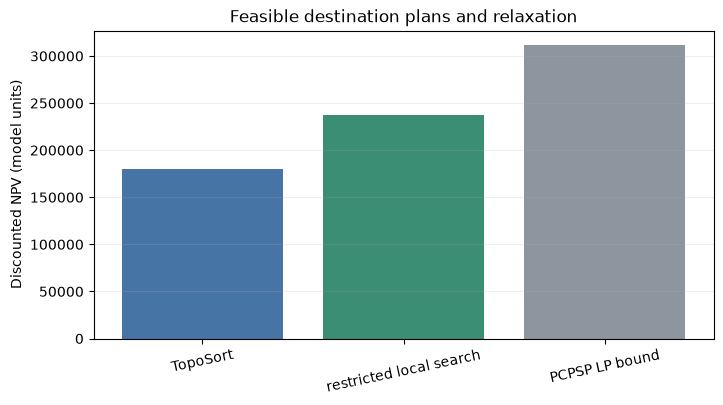

In [8]:
# Compare feasible methods with the PCPSP relaxation bound.
fig, ax = plt.subplots(figsize=(8, 4))
labels = ['TopoSort', 'restricted local search', 'PCPSP LP bound']
values = [destination_plan.npv, improved_npv, relaxation.bound]
colors = ['#4674a5', '#3b8d73', '#8d969f']
ax.bar(labels, values, color=colors)
ax.set(title='Feasible destination plans and relaxation',
       ylabel='Discounted NPV (model units)')
ax.tick_params(axis='x', rotation=12)
ax.grid(axis='y', alpha=0.2)
plt.show()

The first two bars are feasible PCPSP plans and the last is an LP upper bound for the same destination-choice formulation. A higher local-search bar is a measured feasible improvement, not a proof that the full mixed-integer model is optimal. If the bars tie, the bounded neighborhood search found no accepted improving move in this run; that outcome says nothing about unvisited neighborhoods. The CPIT comparator is kept out of this denominator because its fixed-destination formulation is different.

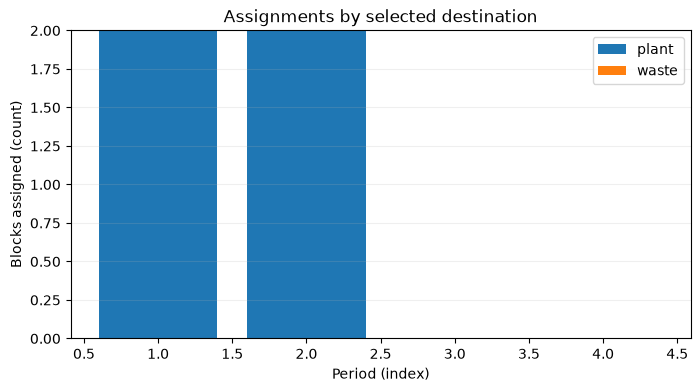

In [9]:
# Plot the final plan's per-period destination counts.
fig, ax = plt.subplots(figsize=(8, 4))
plant_counts = [int(np.sum((improved_plan.period_of_block == t) &
                            (improved_plan.destination_of_block == 1)))
                for t in range(instance.pcpsp.n_periods)]
waste_counts = [int(np.sum((improved_plan.period_of_block == t) &
                            (improved_plan.destination_of_block == 0)))
                for t in range(instance.pcpsp.n_periods)]
periods = np.arange(1, instance.pcpsp.n_periods + 1)
ax.bar(periods, plant_counts, label='plant')
ax.bar(periods, waste_counts, bottom=plant_counts, label='waste')
ax.set(title='Assignments by selected destination',
       xlabel='Period (index)', ylabel='Blocks assigned (count)')
ax.legend()
ax.grid(axis='y', alpha=0.2)
plt.show()

The stacked bars expose how the destination mix changes across periods in the improved schedule. They count assignments, not tonnage or value, and do not encode grade or resource use; those require the block economics and the preceding capacity plot. A plant count can fall because of precedence, remaining capacity or the value trade-off. The figure describes this seed and scenario only; it is not a cutoff curve or a rule for another deposit.

## Results

**Answer:** Destination-aware TopoSort returned 179593.14, while the restricted local re-solve returned 237344.67; the PCPSP LP bound was 311484.31. The local result mines 4 blocks versus TopoSort's 16 because the objective rewards discounted value rather than block count. The re-solve is exact only inside chosen neighborhoods; the full schedule is not certified optimal.



In [10]:
# Report the values used in the Results answer.
print(f'start={destination_plan.npv:.2f}; improved={improved_npv:.2f}; bound={relaxation.bound:.2f}')

start=179593.14; improved=237344.67; bound=311484.31


## Summary

The notebook has run the PCPSP relaxation, destination-aware TopoSort, restricted exact re-solves, and the fixed-destination reduction on one seeded instance. Their outputs answer different questions. Preserve formulation labels, the chosen destination arrays, resource reconciliation, and solver budgets whenever using these methods on another case.

## References

- Jelvez, Morales and Nancel-Penard (2018), destination-aware open-pit scheduling: https://www.delphoslab.cl/Publicaciones/2018/Jelvez_et_al_MPES2018.pdf
- PhaseFlow synthetic instance builder and pipeline: https://github.com/fsantibanezleal/CAOS_PhaseFlow
- PhaseFlow dossier: docs/methodologies/09_destinations.md